# Differencing Experiment Explorer

Compare differencing experiments for a given target variable. Shows lag sweep results, model comparison, and the best run's predictions.

In [24]:
import json, os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(rc={'figure.figsize': (14, 5)})
sns.set_style('whitegrid')
sns.set_context('notebook')\

# --- Configuration ---
#TARGET = 'Steam_power'  # change this to explore other targets
#TARGET = 'Steam_power_corrected'
#TARGET =  "Steam__kWh/T_"
#TARGET = 'Electrical_power_MW'
#TARGET = 'Electricity__kWh/T_'
#TARGET = "Starch_uptake_by_paper_Top_Roll__g/m2_"
#TARGET = "Starch_uptake_by_paper_Bottom_Roll__g/m2_"
TARGET = "MBS_SCT_CD"
#TARGET = "MBS_SCT_MD"
#TARGET = "MBS_Burst"
#TARGET = "MBS_CMT30"
BASE_DIR = Path('experiments/differencing') / TARGET.replace('/', '_')

EWM_HALFLIFE = "6h"

# --- Load all results ---
rows = []
for run_dir in sorted(BASE_DIR.iterdir()):
    rpath = run_dir / 'results.json'
    if not rpath.exists():
        continue
    r = json.load(open(rpath))
    p = r['parameters']
    m = r['metrics']
    d = r['data']

    row = {
        'id': run_dir.name,
        'model': p['model'],
        'lag_days': p['lag_days'],
        'ewm_halflife': p.get('ewm_halflife', '120min'),
        'ridge_alpha': p.get('ridge_alpha'),
        'n_features': d['n_features'],
        'n_samples': d['n_samples'],
        'n_train': d['n_train_contrasts'],
        'n_test': d['n_test_contrasts'],
        'fs_k_features': p.get('fs_k_features'),
        'r2_dy': m['dy']['r2'],
        'rmse_dy': m['dy']['rmse'],
        'r2_ewm_model': m['ewm_model']['r2'],
        'r2_ewm_persist': m['ewm_persistence']['r2'],
        'r2_raw_model': m['raw_model']['r2'],
        'r2_raw_persist': m['raw_persistence']['r2'],
        'gain_ewm': m['gain_over_persistence_ewm'],
        'gain_raw': m['gain_over_persistence_raw'],
    }
    # CI alpha: only include when this run recorded it (CI runs, newer results.json)
    if p.get('ci_alpha') is not None:
        row['ci_alpha'] = p['ci_alpha']
        
    rows.append(row)


df = pd.DataFrame(rows)
print(f'Found {len(df)} experiments for target: {TARGET}')
df.sort_values('r2_ewm_model', ascending=False, inplace=True)
df.reset_index(drop=True, inplace=True)
df


Found 11 experiments for target: MBS_SCT_CD


,id,model,lag_days,ewm_halflife,ridge_alpha,n_features,n_samples,n_train,n_test,fs_k_features,r2_dy,rmse_dy,r2_ewm_model,r2_ewm_persist,r2_raw_model,r2_raw_persist,gain_ewm,gain_raw,ci_alpha
0,261119074059,ridge,0.10,6h,117.210230,21,4732,3249,776,None,0.368684,0.018896,0.987902,0.980801,0.880447,0.822014,0.007102,0.058434,0.07
1,261119073906,ridge,0.10,6h,117.210230,21,4732,3249,776,None,0.368684,0.018896,0.987902,0.980801,0.880447,0.822014,0.007102,0.058434,0.06
2,261119073719,ridge,0.10,6h,117.210230,21,4732,3249,776,None,0.368684,0.018896,0.987902,0.980801,0.880447,0.822014,0.007102,0.058434,0.05
3,261119074502,ridge,0.10,6h,117.210230,21,4732,3249,776,None,0.368684,0.018896,0.987902,0.980801,0.880447,0.822014,0.007102,0.058434,0.09
4,261119074259,ridge,0.10,6h,117.210230,21,4732,3249,776,None,0.368684,0.018896,0.987902,0.980801,0.880447,0.822014,0.007102,0.058434,0.08
5,261119074701,ridge,0.10,6h,117.210230,22,4732,3249,776,None,0.368631,0.018897,0.987901,0.980801,0.880688,0.822014,0.007100,0.058675,0.10
6,261119073526,ridge,0.10,6h,117.210230,20,4732,3249,776,None,0.363285,0.018976,0.987799,0.980801,0.880229,0.822014,0.006998,0.058215,0.04
7,261119073341,ridge,0.10,6h,117.210230,18,4732,3249,776,None,0.359598,0.019031,0.987728,0.980801,0.880024,0.822014,0.006927,0.058011,0.03
8,261119073201,ridge,0.10,6h,85.316785,16,4732,3249,776,None,0.356302,0.019080,0.987665,0.980801,0.880009,0.822014,0.006864,0.057996,0.02
9,261119073021,ridge,0.10,6h,62.101694,14,4732,3249,776,None,0.354117,0.019113,0.987623,0.980801,0.879823,0.822014,0.006822,0.057809,0.01


## Comparison Table

In [25]:
cols = ['id', 'model', 'lag_days', 'ewm_halflife', 'n_features', 'fs_k_features','ci_alpha',
        'r2_dy', 'r2_ewm_model', 'r2_raw_model', 'gain_ewm', 'gain_raw', 'ridge_alpha']
df[cols].style.format({
    'r2_dy': '{:+.4f}', 'r2_ewm_model': '{:+.4f}', 'r2_raw_model': '{:+.4f}',
    'gain_ewm': '{:+.4f}', 'gain_raw': '{:+.4f}', 'ridge_alpha': '{:.1f}',
    'lag_days': '{:.2f}',
}).background_gradient(subset=['r2_dy', 'r2_raw_model'], cmap='RdYlGn')

,id,model,lag_days,ewm_halflife,n_features,fs_k_features,ci_alpha,r2_dy,r2_ewm_model,r2_raw_model,gain_ewm,gain_raw,ridge_alpha
0,261119074059,ridge,0.10,6h,21,None,0.070000,+0.3687,+0.9879,+0.8804,+0.0071,+0.0584,117.2
1,261119073906,ridge,0.10,6h,21,None,0.060000,+0.3687,+0.9879,+0.8804,+0.0071,+0.0584,117.2
2,261119073719,ridge,0.10,6h,21,None,0.050000,+0.3687,+0.9879,+0.8804,+0.0071,+0.0584,117.2
3,261119074502,ridge,0.10,6h,21,None,0.090000,+0.3687,+0.9879,+0.8804,+0.0071,+0.0584,117.2
4,261119074259,ridge,0.10,6h,21,None,0.080000,+0.3687,+0.9879,+0.8804,+0.0071,+0.0584,117.2
5,261119074701,ridge,0.10,6h,22,None,0.100000,+0.3686,+0.9879,+0.8807,+0.0071,+0.0587,117.2
6,261119073526,ridge,0.10,6h,20,None,0.040000,+0.3633,+0.9878,+0.8802,+0.0070,+0.0582,117.2
7,261119073341,ridge,0.10,6h,18,None,0.030000,+0.3596,+0.9877,+0.8800,+0.0069,+0.0580,117.2
8,261119073201,ridge,0.10,6h,16,None,0.020000,+0.3563,+0.9877,+0.8800,+0.0069,+0.0580,85.3
9,261119073021,ridge,0.10,6h,14,None,0.010000,+0.3541,+0.9876,+0.8798,+0.0068,+0.0578,62.1


## Model Comparison

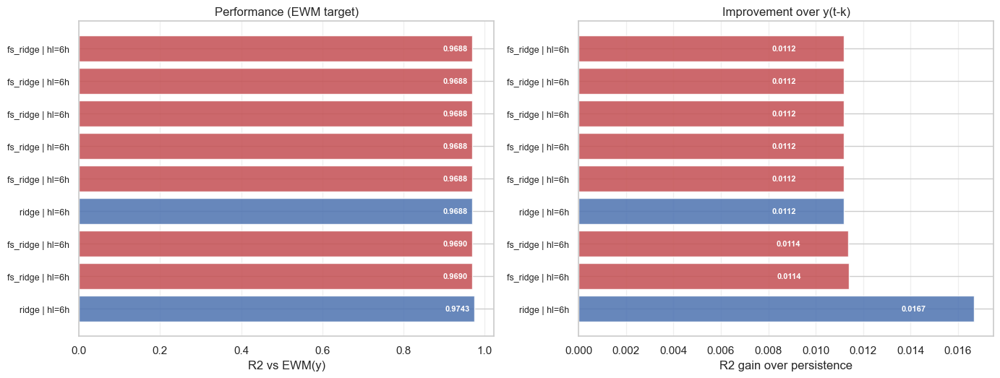

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(df) * 0.6)))

# Simple labels: model + halflife (lag is tuned, so it's always the same)
labels = [f"{r['model']} | hl={r['ewm_halflife']}" for _, r in df.iterrows()]
colors = {'ridge': 'C0', 'splines': 'C1', 'realmlp': 'C2'}
bar_colors = [colors.get(m, 'C3') for m in df['model']]

# Left: R2 vs EWM(y)
ax = axes[0]
ax.barh(range(len(df)), df['r2_ewm_model'], color=bar_colors, alpha=0.85)
ax.set_yticks(range(len(df))); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('R2 vs EWM(y)')
ax.set_title('Performance (EWM target)')
ax.grid(alpha=0.3, axis='x')
# Annotate values
for j, v in enumerate(df['r2_ewm_model']):
    ax.text(v - 0.01, j, f'{v:.4f}', va='center', ha='right', fontsize=8, color='white', fontweight='bold')

# Right: Gain over persistence
ax = axes[1]
ax.barh(range(len(df)), df['gain_ewm'], color=bar_colors, alpha=0.85)
ax.set_yticks(range(len(df))); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('R2 gain over persistence')
ax.set_title('Improvement over y(t-k)')
ax.grid(alpha=0.3, axis='x')
for j, v in enumerate(df['gain_ewm']):
    ax.text(v - 0.002, j, f'{v:.4f}', va='center', ha='right', fontsize=8, color='white', fontweight='bold')

plt.tight_layout()


## Best Experiment

Best: 261118222117
  model=ridge, lag=0.10d, ewm=6h
  R2(dy)=+0.3932
  R2 vs EWM(y): +0.9871 (persistence: +0.9787)
  R2 vs raw y:  +0.8984 (persistence: +0.8918)
  gain over persistence (EWM): +0.0084
  gain over persistence (raw): +0.0067

--- Lag sweep (train CV) ---


,lag_days,cv_rmse,persistence_rmse,cv_r2,n_contrasts
0,0.05,0.021239,0.031239,0.537752,2228
1,0.10,0.036188,0.059550,0.630706,2223
2,0.25,0.078263,0.123697,0.599690,1923
3,0.50,0.126010,0.185626,0.539175,1482
4,1.00,0.173884,0.272111,0.591656,798
5,2.00,0.328420,0.551258,0.645065,315
6,7.00,0.392419,0.490507,0.359958,1397
7,14.00,0.388357,0.497087,0.389625,953


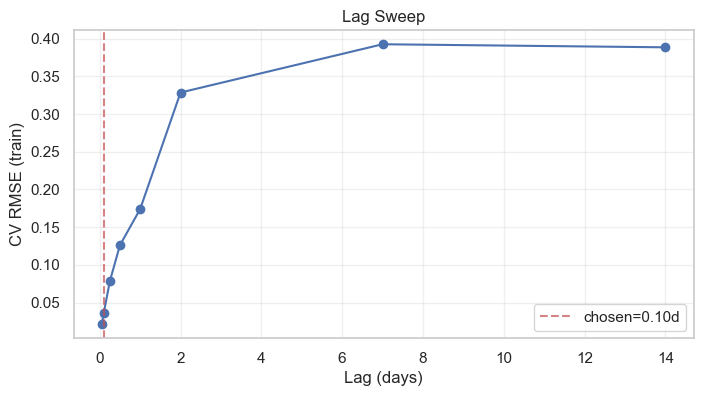

In [18]:
mask = df['ewm_halflife'].astype(str) == EWM_HALFLIFE 
#mask = (df['ewm_halflife'].astype(str) == EWM_HALFLIFE) & (df['fs_k_features'].isnull() | (df['fs_k_features'].astype('Int64') > 10))
df_hl = df[mask].sort_values(['r2_dy', 'r2_raw_model'], ascending=False)

if df_hl.empty:
    raise ValueError(
        f"No experiments with ewm_halflife == {EWM_HALFLIFE!r}. "
        f"Available: {sorted(df['ewm_halflife'].astype(str).unique())}"
    )

best = df_hl.iloc[0]
best_path = BASE_DIR / best['id']
print(f"Best: {best['id']}")
print(f"  model={best['model']}, lag={best['lag_days']:.2f}d, ewm={best['ewm_halflife']}")
print(f"  R2(dy)={best['r2_dy']:+.4f}")
print(f"  R2 vs EWM(y): {best['r2_ewm_model']:+.4f} (persistence: {best['r2_ewm_persist']:+.4f})")
print(f"  R2 vs raw y:  {best['r2_raw_model']:+.4f} (persistence: {best['r2_raw_persist']:+.4f})")
print(f"  gain over persistence (EWM): {best['gain_ewm']:+.4f}")
print(f"  gain over persistence (raw): {best['gain_raw']:+.4f}")

# Show lag sweep if available
lag_path = best_path / 'lag_sweep.csv'
if lag_path.exists():
    print('\n--- Lag sweep (train CV) ---')
    lag_df = pd.read_csv(lag_path)
    display(lag_df)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(lag_df['lag_days'], lag_df['cv_rmse'], 'o-')
    ax.axvline(best['lag_days'], ls='--', color='r', alpha=0.7, label=f"chosen={best['lag_days']:.2f}d")
    ax.set_xlabel('Lag (days)'); ax.set_ylabel('CV RMSE (train)')
    ax.set_title('Lag Sweep'); ax.legend(); ax.grid(alpha=0.3)
    plt.show()


## Plots from Best Experiment

Lag: 0.10d | EWM halflife: 6h
  vs EWM(y): persistence R2=0.9787 | model R2=0.9871 | gain=0.0084
  vs raw y:  model R2=0.8984


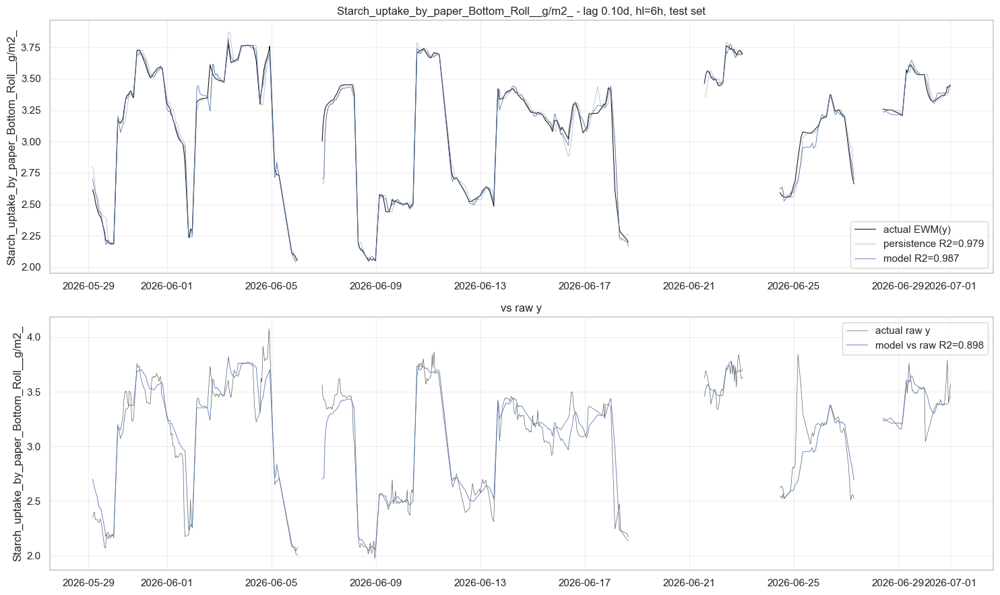

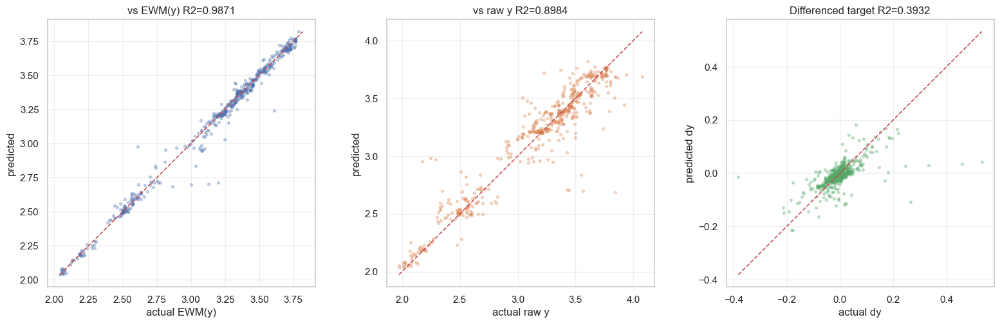

In [19]:
# =============================================================================
# Model Performance Plots (reconstructed from saved data)
# =============================================================================
import sys
from pathlib import Path
import cloudpickle
sys.path.insert(0, str(Path.cwd().parent))

# Load what we need
dy_test = pd.read_parquet(best_path / 'dy_test.parquet')['dy_test'].values
dX_test = pd.read_parquet(best_path / 'dX_test.parquet')
turnup_ts_perf = pd.read_parquet(best_path / 'turnup_ts.parquet')
turnup_ts_raw = pd.read_parquet(best_path / 'turnup_ts_raw.parquet')
results_perf = json.load(open(best_path / 'results.json'))

with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)

raw_model = art['model']
est_perf = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    from sklearn.pipeline import Pipeline as SKPipeline
    est_perf = SKPipeline([('scaler', art['scaler']), ('model', est_perf)])

feat_cols_perf = results_perf['data']['feature_cols']
lag_d = results_perf['parameters']['lag_days']
split_perf = results_perf['data']['split']
ewm_hl = results_perf['parameters'].get('ewm_halflife', '120min')
Y_COL = results_perf['parameters']['y_column']

# Predict on test
# Handle feature selection: if the model used a subset, use only those
selected_feats = art.get('selected_features', feat_cols_perf)
use_cols = [c for c in selected_feats if c in dX_test.columns]
dX_test_feats = dX_test[use_cols].values
dy_pred = est_perf.predict(dX_test_feats).ravel()

# Reconstruct raw-scale predictions
# Need the EWM'd y values at the anchor points
# Re-derive from turnup_ts using the same logic as the script
def ewm_filt(s, halflife=ewm_hl):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

gram_g = turnup_ts_perf['grammage'].values
gc = pd.Series(gram_g).ne(pd.Series(gram_g).shift())
tg = turnup_ts_perf.index.to_series().diff().gt(pd.Timedelta('12h'))
tg.iloc[0] = True
seg_p = (gc.values | tg.values).cumsum()
raw_data = turnup_ts_raw
y_raw_all = raw_data.loc[turnup_ts_perf.index, Y_COL].values
y_ewm_all = turnup_ts_perf[Y_COL].values

# Lag pairing
def to_hours_p(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs_p(t_hours, lag_hours, tolerance=0.35, grammage=None):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    if grammage is not None:
        g = np.asarray(grammage); ok = ok & (g == g[j])
    later = np.flatnonzero(ok)
    return later, j[later]

t_hrs = to_hours_p(turnup_ts_perf.index)
_allow_cross = results_perf['parameters'].get('allow_cross_grammage', True)
_gram_pairs = None if _allow_cross else turnup_ts_perf['grammage'].values
later_all, earlier_all = lag_pairs_p(t_hrs, lag_d * 24.0, grammage=_gram_pairs)
te_mask = later_all >= split_perf
later_te = later_all[te_mask]
earlier_te = earlier_all[te_mask]

t_anchor = turnup_ts_perf.index[later_te]
actual_ewm = y_ewm_all[later_te]
persistence_ewm = y_ewm_all[earlier_te]
model_ewm = persistence_ewm + dy_pred
actual_raw = y_raw_all[later_te]
model_raw = persistence_ewm + dy_pred

from sklearn.metrics import r2_score, mean_absolute_error
r2_pers = r2_score(actual_ewm, persistence_ewm)
r2_mod = r2_score(actual_ewm, model_ewm)
r2_raw = r2_score(actual_raw, model_raw)

print(f'Lag: {lag_d:.2f}d | EWM halflife: {ewm_hl}')
print(f'  vs EWM(y): persistence R2={r2_pers:.4f} | model R2={r2_mod:.4f} | gain={r2_mod-r2_pers:.4f}')
print(f'  vs raw y:  model R2={r2_raw:.4f}')

# --- Time series plot ---
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# Break gaps
dt_h = np.diff(pd.DatetimeIndex(t_anchor).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)

def gapped(vals, gaps):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

axes[0].plot(t_anchor, gapped(actual_ewm, gaps), lw=0.8, color='k', label='actual EWM(y)')
axes[0].plot(t_anchor, gapped(persistence_ewm, gaps), lw=0.5, color='C7', alpha=0.7,
             label=f'persistence R2={r2_pers:.3f}')
axes[0].plot(t_anchor, gapped(model_ewm, gaps), lw=0.7, color='C0', alpha=0.85,
             label=f'model R2={r2_mod:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'{Y_COL} - lag {lag_d:.2f}d, hl={ewm_hl}, test set')
axes[0].set_ylabel(Y_COL)

axes[1].plot(t_anchor, gapped(actual_raw, gaps), lw=0.5, color='k', alpha=0.7, label='actual raw y')
axes[1].plot(t_anchor, gapped(model_raw, gaps), lw=0.7, color='C0', alpha=0.85,
             label=f'model vs raw R2={r2_raw:.3f}')
axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title(f'vs raw y'); axes[1].set_ylabel(Y_COL)

plt.tight_layout()
plt.show()

# --- Scatter plots ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# EWM scatter
axes[0].scatter(actual_ewm, model_ewm, s=8, alpha=0.3)
lim = [min(actual_ewm.min(), model_ewm.min()), max(actual_ewm.max(), model_ewm.max())]
axes[0].plot(lim, lim, 'r--', lw=1.2)
axes[0].set_xlabel('actual EWM(y)'); axes[0].set_ylabel('predicted')
axes[0].set_title(f'vs EWM(y) R2={r2_mod:.4f}')
axes[0].set_aspect('equal', adjustable='box'); axes[0].grid(alpha=0.3)

# Raw scatter
axes[1].scatter(actual_raw, model_raw, s=8, alpha=0.3, color='C1')
lim = [min(actual_raw.min(), model_raw.min()), max(actual_raw.max(), model_raw.max())]
axes[1].plot(lim, lim, 'r--', lw=1.2)
axes[1].set_xlabel('actual raw y'); axes[1].set_ylabel('predicted')
axes[1].set_title(f'vs raw y R2={r2_raw:.4f}')
axes[1].set_aspect('equal', adjustable='box'); axes[1].grid(alpha=0.3)

# dy scatter
r2_dy = r2_score(dy_test, dy_pred)
axes[2].scatter(dy_test, dy_pred, s=8, alpha=0.3, color='C2')
lim = [min(dy_test.min(), dy_pred.min()), max(dy_test.max(), dy_pred.max())]
axes[2].plot(lim, lim, 'r--', lw=1.2)
axes[2].set_xlabel('actual dy'); axes[2].set_ylabel('predicted dy')
axes[2].set_title(f'Differenced target R2={r2_dy:.4f}')
axes[2].set_aspect('equal', adjustable='box'); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Model

In [73]:
import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import _feature_engineering, setpoint_df
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

turnup_data = pd.read_parquet('../data/costimiser_turnup.parquet')
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index('Wedge_Time').sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100, 90, 85, 110])]
turnup_ts = turnup_data.copy().sort_index()


In [8]:
turnup_data = turnup_data[turnup_data.index>"2026-01-01"]
#turnup_data = turnup_data[turnup_data.index>"2025-11-15"]
turnup_data = turnup_data[turnup_data.index < "2026-07-1"]

In [93]:
[ v for v in turnup_data.columns if "temperature" in v.lower()]

['DG4_Temperature_Inlet_Air',
 'DG5_Temperature_Inlet_Air',
 'AirTurn_Temperature',
 'Reactor_Temperature',
 'Temperature_inactivation',
 'Storage_tank_temperature',
 'Temperature_starch_working_tank_1',
 'Temperature_starch_working_tank_2',
 'Cylinder_1-5_steam_temperature',
 'Inlet_Air_2_Temperature',
 'Inlet_Air_1_Temperature',
 'DG1_temperature_Inlet_Air',
 'DG2_temperature_Inlet_Air',
 'DG3_temperature_Inlet_Air',
 'White_water_temperature',
 'Dilution_water_deculator_temperature',
 'Stock_deculator_temperature',
 'Steam_temperature_for_PM',
 'Temperature_working_tank_to_bottom_roll']

In [85]:
[v for v in turnup_data.columns if "wet" in v.lower()]

['Vacuum_wet_suction_box', 'Wet_broke_flow', 'Wet_broke_consistency']

In [86]:
turnup_data["dry_broke"] = turnup_data["Dry_broke_flow"]*turnup_data["Dry_Broke_Consistancy__%_"] / turnup_data["Production_Rate__T/h_"] /6000
turnup_data["wet_broke"] = turnup_data["Wet_broke_flow"]*turnup_data["Wet_broke_consistency"] / turnup_data["Production_Rate__T/h_"] /6000

<Axes: xlabel='Steam_flow_to_white_water_heating', ylabel='Steam__kWh/T_'>

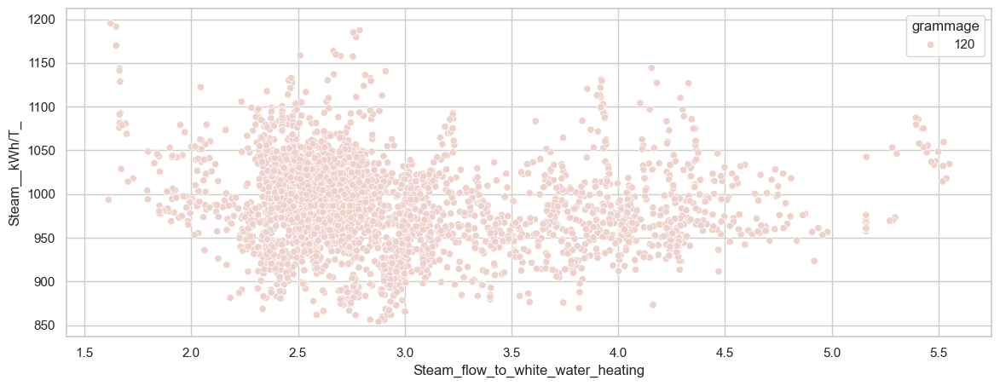

In [92]:
sns.scatterplot(turnup_data[turnup_data.grammage==120], x='Steam_flow_to_white_water_heating', y="Steam__kWh/T_", hue="grammage")

<Axes: xlabel='Dewatering_Shoe_press', ylabel='Steam__kWh/T_'>

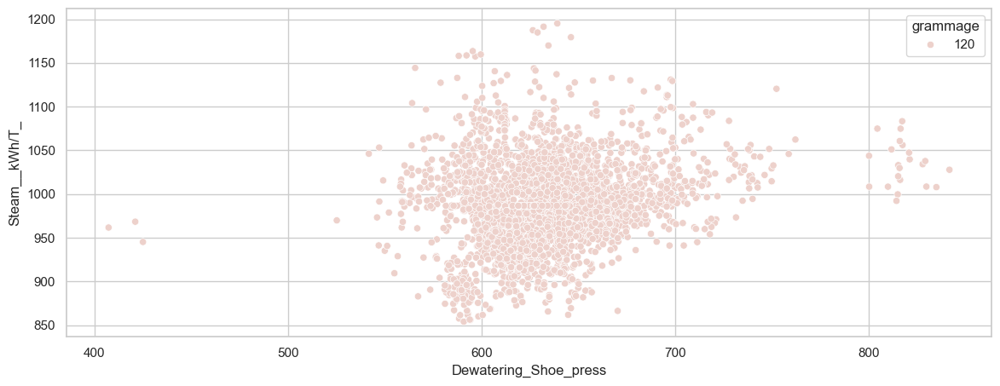

In [9]:
sns.scatterplot(turnup_data[turnup_data.grammage==120], x='Dewatering_Shoe_press', y="Steam__kWh/T_", hue="grammage")

<Axes: xlabel='DG1_Moisture_content_Outlet_Air', ylabel='Steam__kWh/T_'>

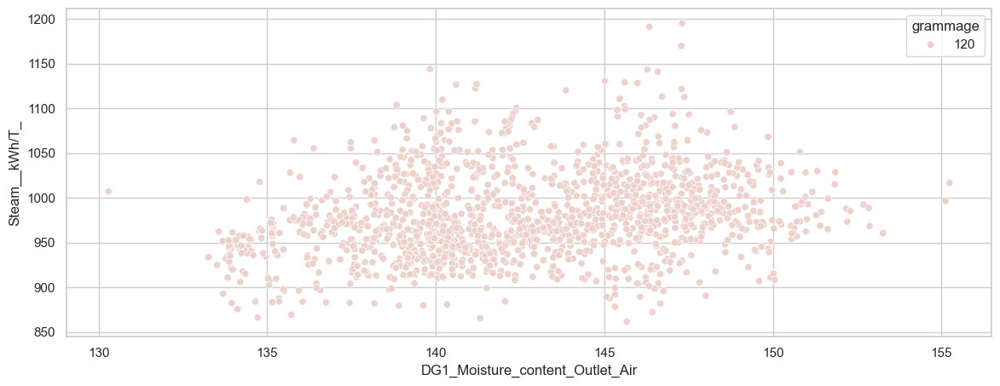

In [32]:
sns.scatterplot(turnup_data[turnup_data.grammage==120], x='DG1_Moisture_content_Outlet_Air', y="Steam__kWh/T_", hue="grammage")

<Axes: xlabel='DG1_Moisture_content_Outlet_Air', ylabel='Steam_power_corrected'>

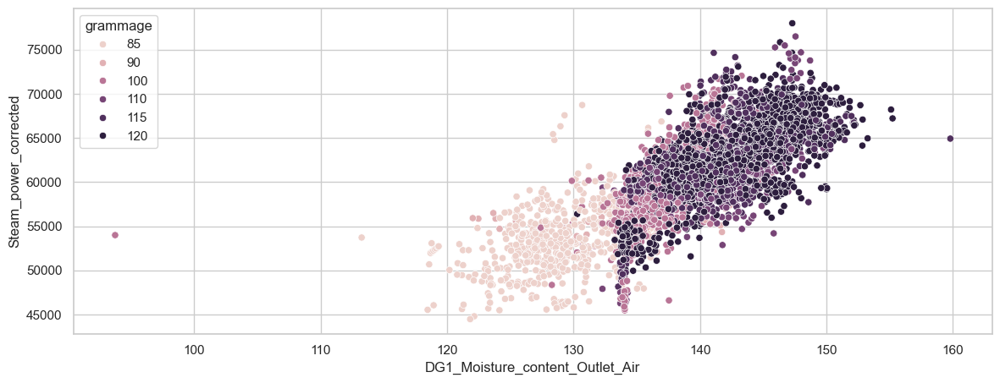

In [31]:
sns.scatterplot(turnup_data, x='DG1_Moisture_content_Outlet_Air', y="Steam_power_corrected", hue="grammage")

<Axes: xlabel='Viscosity_for_working_tank_bottom_roll', ylabel='MBS_SCT_CD'>

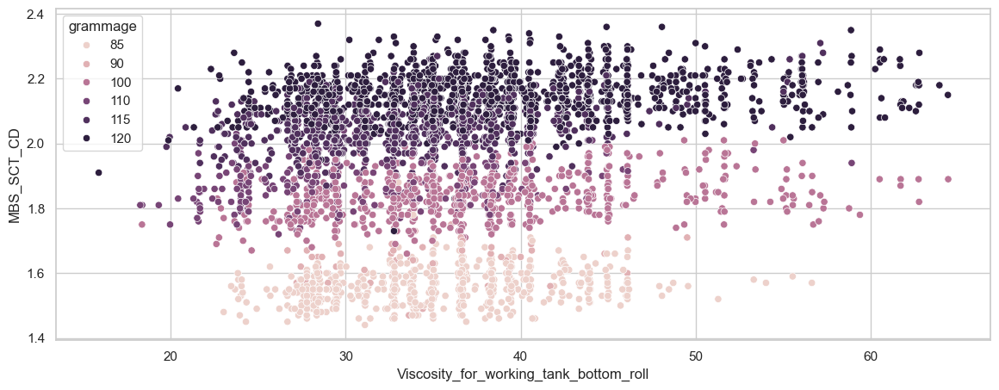

In [97]:
sns.scatterplot(turnup_data, x='Viscosity_for_working_tank_bottom_roll', y="MBS_SCT_CD", hue="grammage")

In [41]:
import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import _feature_engineering, setpoint_df
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

# --- Load experiment artifacts ---
results_abs = json.load(open(best_path / 'results.json'))
with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)

Y_COLUMN = results_abs['parameters']['y_column']
lag_days = results_abs['parameters']['lag_days']
ewm_halflife = results_abs['parameters'].get('ewm_halflife', '120min')
feature_cols = results_abs['data']['feature_cols']
feat_list = art['feat_list']
pre_estimator = art['pre_estimator']
selected_features = art.get('selected_features', feature_cols)

# Get the fitted model
raw_model = art['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    est = SKPipeline([('scaler', art['scaler']), ('model', est)])

state_col = Y_COLUMN + '_state'

# Extract the exact test period from the experiment's turnup_ts
split_orig = results_abs['data']['split']
ts_artifact = pd.read_parquet(best_path / 'turnup_ts.parquet')
test_start = ts_artifact.index[split_orig]
test_end = ts_artifact.index[-1]
print(f'Experiment test period: {test_start} -> {test_end}')

# --- Load and prepare data ---
turnup_data = pd.read_parquet('../data/costimiser_turnup.parquet')
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index('Wedge_Time').sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100, 90, 85, 110])]
turnup_ts = turnup_data.copy().sort_index()

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days}d, EWM halflife: {ewm_halflife}')
print(f'Pipeline steps: {[n for n, _ in pre_estimator.steps]}')
print(f'Selected features: {len(selected_features)}')
print(f'turnup_ts: {turnup_ts.shape}')

# --- EWM filter raw columns (data prep, not part of the model) ---
def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
seg = (grade_change.values | time_gap.values).cumsum()

y_raw = turnup_ts[Y_COLUMN].values.copy()

for col in feat_list:
    if col in turnup_ts.columns and pd.api.types.is_numeric_dtype(turnup_ts[col]):
        s = pd.Series(turnup_ts[col].values, index=turnup_ts.index)
        turnup_ts[col] = s.groupby(seg).transform(
            lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

y_ewm = pd.Series(y_raw, index=turnup_ts.index).groupby(seg).transform(
    lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

Experiment test period: 2026-05-29 03:47:30 -> 2026-06-30 23:59:30
Target: Steam__kWh/T_
Lag: 0.25d, EWM halflife: 6h
Pipeline steps: ['feat', 'inlet_temp', 'linepressure', 'filter', 'scaler_encoder']
Selected features: 23
turnup_ts: (9628, 558)


In [42]:
feature_cols

['Jet/wire_ratio',
 'Speed',
 'Consistency_starch_main_line',
 'Moisture_after_SpeedSizer',
 'Current_reel_moisture_average(SpeedSizer)',
 'Cylinder_1-5_fresh_steam',
 'PickUp_Tension',
 'Sludge_addition_to_stock',
 'Dry_Broke_Consistancy__%_',
 'Contaminex_3_power',
 'LF_screen_3_power',
 'Pressure_main_steam_line',
 'Condensate_conductivity',
 'Concentration_of_starch_to_bottom_roll',
 'Viscosity_for_starch_ring_main_line',
 'Draw_PD4-PD5',
 'Fixative_2_mass_flow__g/T_',
 'Starch_mass_flow__kg/T_',
 'ambient_temp_C',
 'Starch_uptake__g/m2_',
 'Production_Rate__T/h_',
 'inlet_temp_2',
 'linepressure_1']

Experiment test period: 2026-05-29 03:47:30 -> 2026-06-30 23:59:30
Target: Steam__kWh/T_
Lag: 0.1d, EWM halflife: 6h
Pipeline steps: ['feat', 'inlet_temp', 'filter', 'scaler_encoder']
Selected features: 25
turnup_ts: (9628, 558)

Added "Steam__kWh/T__state": 8154 valid values

=== Absolute model (stored beta, no refit) ===
  Test period: 2026-05-29 03:47:30 -> 2026-06-30 23:59:30
  Test rows: 512
  R2 vs EWM(y): 0.9504
  R2 vs raw y:  0.6026
  std(beta'X): 12.98  (regression)
  std(c):       20.42  (state)


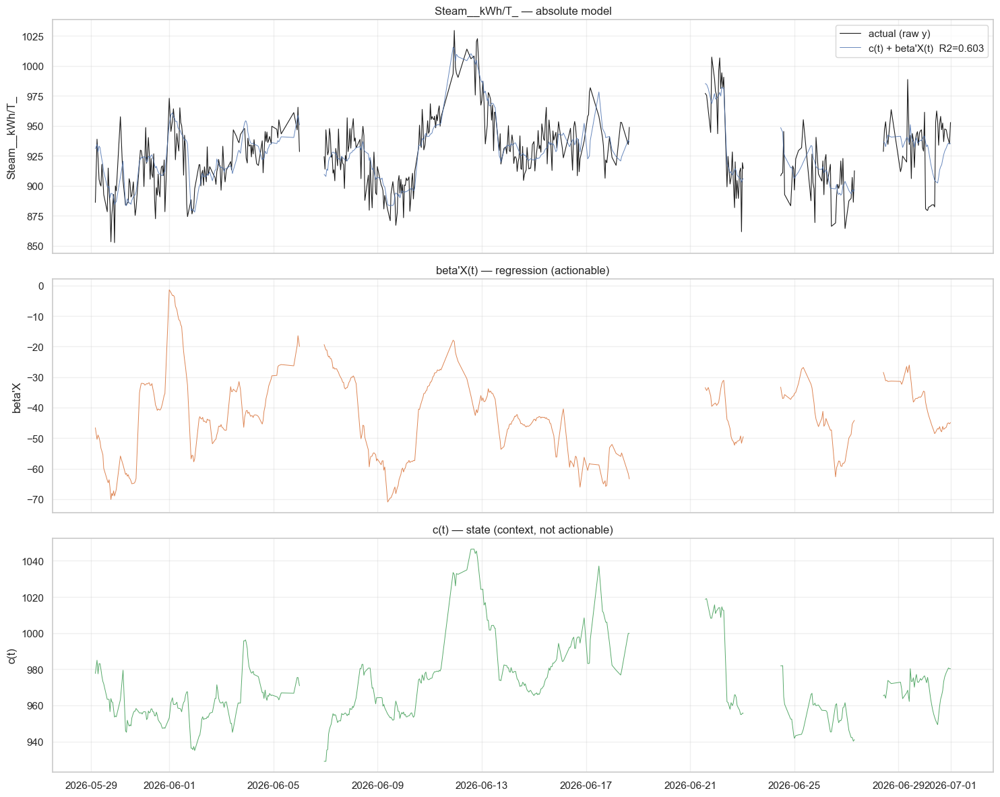

In [157]:
%matplotlib inline
# =============================================================================
# Extract fitted model and compute state column
# =============================================================================

import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import _feature_engineering, setpoint_df
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

# --- Load experiment artifacts ---
results_abs = json.load(open(best_path / 'results.json'))
with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)

Y_COLUMN = results_abs['parameters']['y_column']
lag_days = results_abs['parameters']['lag_days']
ewm_halflife = results_abs['parameters'].get('ewm_halflife', '120min')
feature_cols = results_abs['data']['feature_cols']
feat_list = art['feat_list']
pre_estimator = art['pre_estimator']
selected_features = art.get('selected_features', feature_cols)

# Get the fitted model
raw_model = art['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    est = SKPipeline([('scaler', art['scaler']), ('model', est)])

state_col = Y_COLUMN + '_state'

# Extract the exact test period from the experiment's turnup_ts
split_orig = results_abs['data']['split']
ts_artifact = pd.read_parquet(best_path / 'turnup_ts.parquet')
test_start = ts_artifact.index[split_orig]
test_end = ts_artifact.index[-1]
print(f'Experiment test period: {test_start} -> {test_end}')

# --- Load and prepare data ---
turnup_data = pd.read_parquet('../data/costimiser_turnup.parquet')
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index('Wedge_Time').sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100, 90, 85, 110])]
if Y_COLUMN == "MBS_CMT30":
    turnup_data = turnup_data[(turnup_data["AB_Grade_ID"]=="6010120") |  (turnup_data["AB_Grade_ID"]=="6010100")]
turnup_ts = turnup_data.copy().sort_index()

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days}d, EWM halflife: {ewm_halflife}')
print(f'Pipeline steps: {[n for n, _ in pre_estimator.steps]}')
print(f'Selected features: {len(selected_features)}')
print(f'turnup_ts: {turnup_ts.shape}')

# --- EWM filter raw columns (data prep, not part of the model) ---
def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
seg = (grade_change.values | time_gap.values).cumsum()

y_raw = turnup_ts[Y_COLUMN].values.copy()

for col in feat_list:
    if col in turnup_ts.columns and pd.api.types.is_numeric_dtype(turnup_ts[col]):
        s = pd.Series(turnup_ts[col].values, index=turnup_ts.index)
        turnup_ts[col] = s.groupby(seg).transform(
            lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

y_ewm = pd.Series(y_raw, index=turnup_ts.index).groupby(seg).transform(
    lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

# --- Transform through pipeline (no EWM inside) ---
available_cols = [c for c in feat_list if c in turnup_ts.columns]
ts_transformed = pre_estimator.transform(turnup_ts.loc[:, available_cols])

# --- Compute beta'X for all rows ---
X_all = ts_transformed[selected_features].values.astype(float)
beta_X_all = est.predict(X_all).ravel()

# --- Lag pairing ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35, grammage=None):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    if grammage is not None:
        g = np.asarray(grammage); ok = ok & (g == g[j])
    later = np.flatnonzero(ok)
    return later, j[later]

t_hours = to_hours(ts_transformed.index)
_allow_cross = results_abs['parameters'].get('allow_cross_grammage', True)
_gram_pairs = None if _allow_cross else turnup_ts['grammage'].values[:len(ts_transformed)]
later, earlier = lag_pairs(t_hours, lag_days * 24.0, grammage=_gram_pairs)

# --- Compute state: c(t) = y_ewm(t-k) - beta'X(t-k) ---
c = y_ewm[earlier] - beta_X_all[earlier]

turnup_ts[state_col] = np.nan
turnup_ts.iloc[later, turnup_ts.columns.get_loc(state_col)] = c
print(f'\nAdded "{state_col}": {turnup_ts[state_col].notna().sum()} valid values')

# --- Evaluate on the EXPERIMENT'S test period ---
y_hat = c + beta_X_all[later]
y_actual_ewm = y_ewm[later]
y_actual_raw = y_raw[later]
t_index = ts_transformed.index[later]

# Use the experiment's test boundary, not a recomputed split
test_mask = (t_index >= test_start) & (t_index <= test_end)

r2_ewm = r2_score(y_actual_ewm[test_mask], y_hat[test_mask])
r2_raw = r2_score(y_actual_raw[test_mask], y_hat[test_mask])

print(f'\n=== Absolute model (stored beta, no refit) ===')
print(f'  Test period: {t_index[test_mask][0]} -> {t_index[test_mask][-1]}')
print(f'  Test rows: {test_mask.sum()}')
print(f'  R2 vs EWM(y): {r2_ewm:.4f}')
print(f'  R2 vs raw y:  {r2_raw:.4f}')
print(f'  std(beta\'X): {np.std(beta_X_all[later[test_mask]]):.2f}  (regression)')
print(f'  std(c):       {np.std(c[test_mask]):.2f}  (state)')

# --- Plot ---
t_test = t_index[test_mask]
dt_h = np.diff(pd.DatetimeIndex(t_test).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)
def gapped(vals):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
axes[0].plot(t_test, gapped(y_actual_raw[test_mask]), lw=0.8, color='k', label='actual (raw y)')
axes[0].plot(t_test, gapped(y_hat[test_mask]), lw=0.7, color='C0', alpha=0.85,
             label=f'c(t) + beta\'X(t)  R2={r2_raw:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'{Y_COLUMN} — absolute model'); axes[0].set_ylabel(Y_COLUMN)

axes[1].plot(t_test, gapped(beta_X_all[later[test_mask]]), lw=0.7, color='C1')
axes[1].set_title("beta'X(t) — regression (actionable)"); axes[1].set_ylabel('beta\'X')
axes[1].grid(alpha=0.3)

axes[2].plot(t_test, gapped(c[test_mask]), lw=0.7, color='C2')
axes[2].set_title('c(t) — state (context, not actionable)'); axes[2].set_ylabel('c(t)')
axes[2].grid(alpha=0.3)
plt.tight_layout()


<Axes: xlabel='Wedge_Time'>

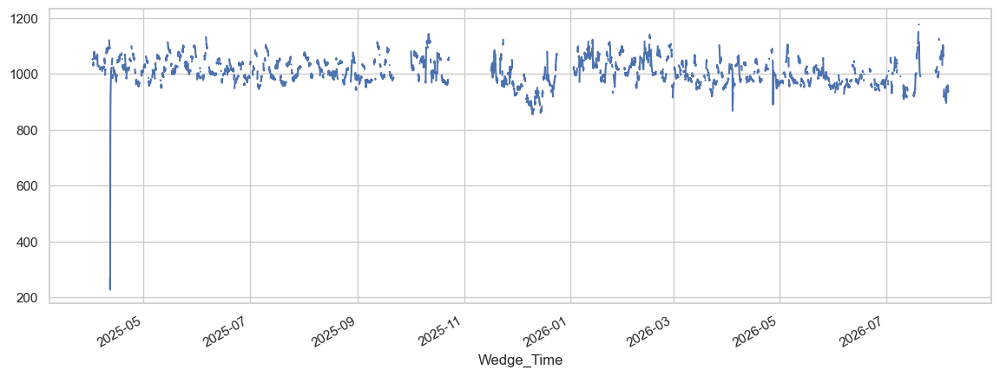

In [158]:
turnup_ts[state_col].plot()

In [159]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
# =============================================================================
# SHAP Analysis using model_full (trained on all data)
# =============================================================================
import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import calculate_manual_shap, plotly_shap_beeswarm

# Load the full model
with open(best_path / 'model_full.pkl', 'rb') as f:
    art_full = cloudpickle.load(f)

# Load differenced data
dX_train = pd.read_parquet(best_path / 'dX_train.parquet')
dX_test = pd.read_parquet(best_path / 'dX_test.parquet')

results_shap = json.load(open(best_path / 'results.json'))
feat_cols_shap = results_shap['data']['feature_cols']
selected_shap = art_full.get('selected_features', feat_cols_shap)

# Get the estimator
raw_model_full = art_full['model']
est_full = getattr(raw_model_full, 'best_estimator_', raw_model_full)
if 'scaler' in art_full and art_full['scaler'] is not None:
    from sklearn.pipeline import Pipeline as SKPipeline
    est_full = SKPipeline([('scaler', art_full['scaler']), ('model', est_full)])

# Use ALL data as both reference and sample (model_full saw everything)
dX_all = pd.concat([dX_train, dX_test], ignore_index=False)

# Keep only selected features + grade col
model_cols = [c for c in selected_shap if c in dX_all.columns]

# Wrap model to drop AB_Grade_ID before predicting
class _ModelWrapperFull:
    def __init__(self, estimator, cols):
        self.estimator = estimator
        self.cols = cols
    def predict(self, X):
        Xf = X[self.cols] if isinstance(X, pd.DataFrame) else X
        return self.estimator.predict(Xf)

wrapped_full = _ModelWrapperFull(est_full, model_cols)

# Compute SHAP
grade_id = '6010120'  # or None for all grades
base, shap_vals, X_explain, feats = calculate_manual_shap(
    wrapped_full,
    X_sample=dX_all[model_cols + ['AB_Grade_ID']],
    X_reference=dX_all[model_cols + ['AB_Grade_ID']],
    grade_col='AB_Grade_ID',
    grade_id=grade_id,
)

print(f'SHAP (model_full): {shap_vals.shape[0]} samples, {shap_vals.shape[1]} features')
print(f'Grade: {grade_id}')

fig = plotly_shap_beeswarm(shap_vals, X_explain, feats, max_features=100)
fig.show()


PermutationExplainer explainer: 1145it [00:40, 20.99it/s]                          


SHAP (model_full): 1144 samples, 25 features
Grade: 6010120


In [97]:
selected_shap

['Speed_Size_Press',
 'Temperature_starch_working_tank_1',
 'Moisture_after_SpeedSizer',
 'Retention_Aid_mass_flow__g/T_',
 'Jet/wire_ratio',
 'White_water_temperature',
 'Top_wire_tenstion',
 'Act_Deaerator_mass_flow__g/T_',
 'Natriumhydroxide_mass_flow__g/T_',
 'delta_basis_weight',
 'retention',
 'speedsizer_linepressure_1',
 'linepressure_1',
 'starch1_1',
 'starch1_2']

In [78]:
feat_list_raw

['Speed',
 'Moisture_after_SpeedSizer',
 'Consistency_starch_main_line',
 'Jet/wire_ratio',
 'Retention_Aid_mass_flow__g/T_',
 'White_water_temperature',
 'grammage',
 'concentration_starch_working_tank_2',
 'concentration_starch_working_tank_1',
 'Viscosity_for_working_tank_bottom_roll',
 'Consistency_white_water',
 'Current_basis_weight',
 'Headbox_consistency',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Starch_uptake_by_paper_Top_Roll__g/m2_']

In [46]:
import warnings
warnings.filterwarnings('ignore')
# =============================================================================
# SHAP on RAW features (direct Ridge on raw differenced data)
# =============================================================================
# Fits a Ridge directly on EWM'd raw features (no PLS, no engineering)
# to get SHAP values on the original column names.

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score

# Load artifacts
results_raw = json.load(open(best_path / 'results.json'))
Y_COL_RAW = results_raw['parameters']['y_column']
lag_raw = results_raw['parameters']['lag_days']
ewm_hl_raw = results_raw['parameters'].get('ewm_halflife', '120min')
split_raw = results_raw['data']['split']

with open(best_path / 'model_full.pkl', 'rb') as f:
    art_raw_full = cloudpickle.load(f)
feat_list_raw = art_raw_full['feat_list']

# Load the EWM'd turnup_ts from artifact
ts_ewm = pd.read_parquet(best_path / 'turnup_ts.parquet')

# Raw numeric columns (exclude AB_Grade_ID and non-numeric)
numeric_cols = [c for c in feat_list_raw
                if c in ts_ewm.columns
                and c != 'AB_Grade_ID'
                and pd.api.types.is_numeric_dtype(ts_ewm[c])]

# Lag pairing
def to_hours_raw(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs_raw(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

t_hrs_raw = to_hours_raw(ts_ewm.index)
later_raw, earlier_raw = lag_pairs_raw(t_hrs_raw, lag_raw * 24.0)

# Differenced raw features
X_raw_all = ts_ewm[numeric_cols].values.astype(float)
y_ewm_raw = ts_ewm[Y_COL_RAW].values.astype(float)
dX_raw_all = X_raw_all[later_raw] - X_raw_all[earlier_raw]
dy_raw_all = y_ewm_raw[later_raw] - y_ewm_raw[earlier_raw]

# Fit Ridge on ALL raw differenced data (matches model_full)
model_raw_full = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
    param_grid={'ridge__alpha': np.logspace(0, 3, 20).tolist()},
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_root_mean_squared_error',
    refit=True,
)
model_raw_full.fit(dX_raw_all, dy_raw_all)

r2_raw_direct = r2_score(dy_raw_all, model_raw_full.predict(dX_raw_all))
r2_prod = results_raw['metrics']['dy']['r2']
print(f'R2(dy) raw features model: {r2_raw_direct:.4f}')
print(f'R2(dy) production model:   {r2_prod:.4f}')
print(f'Gap (PLS/engineering value): {r2_prod - r2_raw_direct:+.4f}')

# SHAP on raw features
dX_raw_df = pd.DataFrame(dX_raw_all, columns=numeric_cols)
dX_raw_df['AB_Grade_ID'] = ts_ewm['AB_Grade_ID'].values[later_raw]

class _RawWrap:
    def __init__(self, model, cols):
        self.model = model
        self.cols = cols
    def predict(self, X):
        Xf = X[self.cols] if isinstance(X, pd.DataFrame) else X
        return self.model.predict(Xf)

wrapped_raw_full = _RawWrap(model_raw_full.best_estimator_, numeric_cols)

grade_id_raw = '6010120'  # or None for all grades
base_r, shap_vals_r, X_explain_r, feats_r = calculate_manual_shap(
    wrapped_raw_full,
    X_sample=dX_raw_df,
    X_reference=dX_raw_df,
    grade_col='AB_Grade_ID',
    grade_id=grade_id_raw,
)

print(f'\nSHAP (raw features, model_full): {shap_vals_r.shape[0]} samples, {shap_vals_r.shape[1]} features')

fig = plotly_shap_beeswarm(shap_vals_r, X_explain_r, feats_r, max_features=50)
fig.show()


R2(dy) raw features model: 0.5060
R2(dy) production model:   0.2474
Gap (PLS/engineering value): -0.2586


PermutationExplainer explainer: 1177it [00:45, 20.17it/s]                          


SHAP (raw features, model_full): 1176 samples, 33 features


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.1 when using version 1.7.2. 

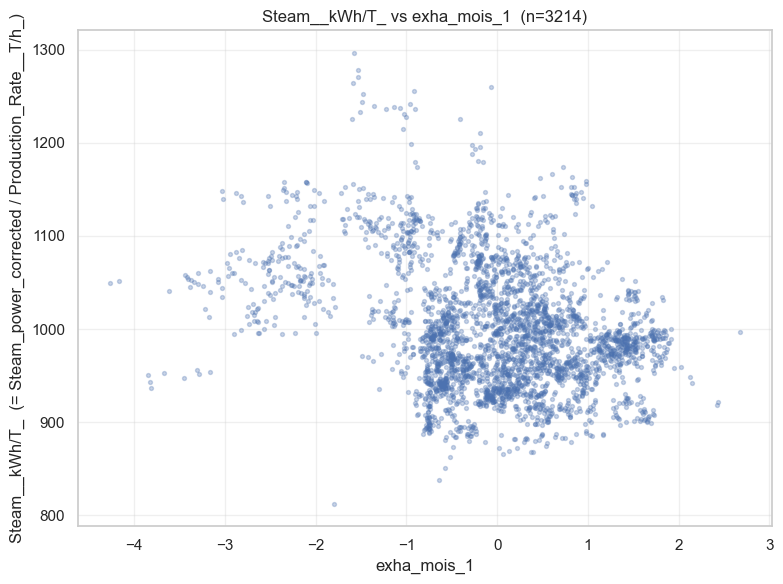

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle
import sys
sys.path.insert(0, str(Path.cwd().parent))
from utility import _feature_engineering, setpoint_df

# --- Load artifact + EWM'd turnup from best_path ---
art = cloudpickle.load(open(best_path / 'model_full.pkl', 'rb'))
pre_estimator = art['pre_estimator']
feat_list     = art['feat_list']

results = json.load(open(best_path / 'results.json'))
y_column = results['parameters']['y_column']          # 'Steam_power_corrected'

ts_ewm = pd.read_parquet(best_path / 'turnup_ts.parquet')   # EWM-filtered turnup

# --- Transform through the preprocessing pipeline ---
avail = [c for c in feat_list if c in ts_ewm.columns]
Xt = pre_estimator.transform(ts_ewm.loc[:, avail])          # transformed features

X_COL = 'exha_mois_1'
if X_COL not in Xt.columns:
    raise KeyError(f"'{X_COL}' not in transformed columns. Available: {list(Xt.columns)}")

# --- Build Steam__kWh/T_ = Steam_power_corrected / Production_Rate (EWM'd) ---
DIVISOR = 'Production_Rate__T/h_'
y_power = ts_ewm[y_column].reindex(Xt.index).astype(float)
prod    = ts_ewm[DIVISOR].reindex(Xt.index).astype(float)
y_specific = y_power / prod
y_specific.name = 'Steam__kWh/T_'

# --- Assemble, drop invalid rows, scatter ---
df = pd.DataFrame({'Steam__kWh/T_': y_specific.values,
                   X_COL: Xt[X_COL].values}, index=Xt.index)
df = df[(prod.values > 0) & np.isfinite(df['Steam__kWh/T_']) & np.isfinite(df[X_COL])]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df[X_COL], df['Steam__kWh/T_'], s=8, alpha=0.3)
ax.set_xlabel(X_COL)
ax.set_ylabel('Steam__kWh/T_  (= Steam_power_corrected / Production_Rate__T/h_)')
ax.set_title(f'Steam__kWh/T_ vs {X_COL}  (n={len(df)})')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.1 when using version 1.7.2. 

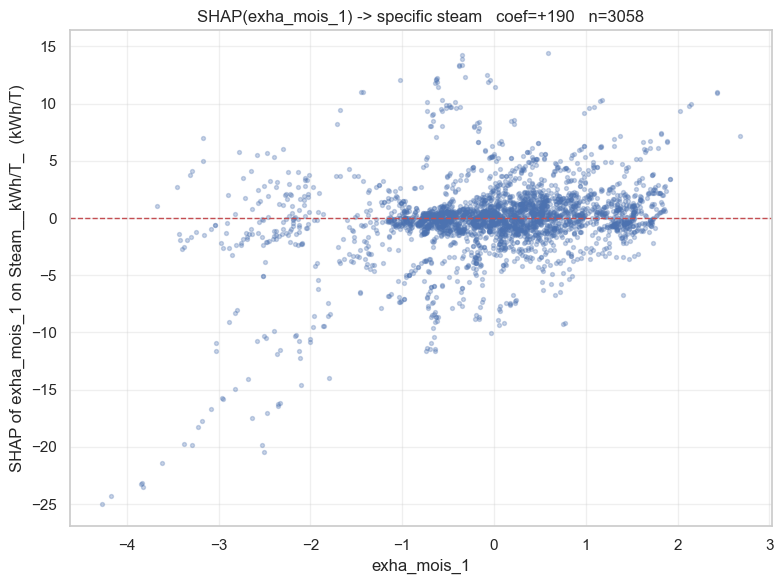

In [10]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle
from sklearn.pipeline import Pipeline as SKPipeline

art = cloudpickle.load(open(best_path / 'model_full.pkl', 'rb'))
results = json.load(open(best_path / 'results.json'))
y_column = results['parameters']['y_column']            # Steam_power_corrected
lag_days = results['parameters']['lag_days']
pre_estimator     = art['pre_estimator']
feat_list         = art['feat_list']
selected_features = art.get('selected_features', results['data']['feature_cols'])
raw_model = art['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    est = SKPipeline([('scaler', art['scaler']), ('model', est)])

FEATURE = 'exha_mois_1'
DIVISOR = 'Production_Rate__T/h_'
jdx = list(selected_features).index(FEATURE)

ts = pd.read_parquet(best_path / 'turnup_ts.parquet')
avail = [c for c in feat_list if c in ts.columns]
Xt = pre_estimator.transform(ts.loc[:, avail])

def to_hours(idx):
    t = pd.DatetimeIndex(idx).asi8.astype(np.float64); return (t - t[0]) / 3.6e12
def lag_pairs(th, lag_h, tol=0.35):
    tgt = th - lag_h; j = np.searchsorted(th, tgt); j = np.clip(j, 0, len(th)-1)
    ja = np.clip(j-1, 0, len(th)-1)
    better = np.abs(th[ja]-tgt) < np.abs(th[j]-tgt); j = np.where(better, ja, j)
    rea = th - th[j]; ok = (j < np.arange(len(th))) & (np.abs(rea-lag_h) <= tol*lag_h)
    later = np.flatnonzero(ok); return later, j[later]

th = to_hours(Xt.index)
later, earlier = lag_pairs(th, lag_days * 24.0)
X_sel = Xt[selected_features].values.astype(float)
dX = X_sel[later] - X_sel[earlier]

scaler = est.named_steps.get('scaler')
ridge  = est.named_steps.get('ridge') or est.named_steps.get('model')
coef   = np.asarray(ridge.coef_).ravel()
Xs = scaler.transform(dX) if scaler is not None else dX

# SHAP of the model target (Δ Steam_power), exact for linear/Ridge:
shap_power = coef[jdx] * (Xs[:, jdx] - Xs[:, jdx].mean())

# Convert to specific-steam contribution. For a feature that does NOT drive
# Production_Rate, specific-steam SHAP = SHAP(power)/P. (If it did drive P, the
# exact ratio derivative would add a -y/P^2 * dP term; exha_mois_1 is a PLS score
# unrelated to P's inputs, so that term is ~0 here.)
P = ts[DIVISOR].reindex(Xt.index).astype(float).values[later]
valid = (P > 0) & np.isfinite(P) & np.isfinite(shap_power)
shap_specific = shap_power[valid] / P[valid]

# IMPORTANT: plot against the SAME x as the scatter (the exha_mois_1 LEVEL at the
# 'later' timestamp), so the SHAP plot is directly comparable to the scatter.
x_level = Xt[FEATURE].values[later][valid]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x_level, shap_specific, s=8, alpha=0.3)
ax.axhline(0, color='r', lw=1, ls='--')
ax.set_xlabel(FEATURE)                                   # LEVEL, matches the scatter x
ax.set_ylabel(f'SHAP of {FEATURE} on Steam__kWh/T_  (kWh/T)')
ax.set_title(f'SHAP({FEATURE}) -> specific steam   coef={coef[jdx]:+.3g}   n={valid.sum()}')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
import json, numpy as np, pandas as pd, cloudpickle
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SKPipeline

art = cloudpickle.load(open(best_path / 'model_full.pkl','rb'))
results = json.load(open(best_path / 'results.json'))
y_column = results['parameters']['y_column']; lag_days = results['parameters']['lag_days']
pre_estimator=art['pre_estimator']; feat_list=art['feat_list']
selected_features = art.get('selected_features', results['data']['feature_cols'])
est = getattr(art['model'],'best_estimator_',art['model'])
if 'scaler' in art and art['scaler'] is not None:
    est = SKPipeline([('scaler',art['scaler']),('model',est)])
ridge = est.named_steps.get('ridge') or est.named_steps.get('model')
coef  = np.asarray(ridge.coef_).ravel()

FEATURE='exha_mois_1'; jdx=list(selected_features).index(FEATURE)

ts = pd.read_parquet(best_path/'turnup_ts.parquet')
Xt = pre_estimator.transform(ts.loc[:,[c for c in feat_list if c in ts.columns]])
def to_hours(i): t=pd.DatetimeIndex(i).asi8.astype(float); return (t-t[0])/3.6e12
def lag_pairs(th,lh,tol=.35):
    tg=th-lh; j=np.clip(np.searchsorted(th,tg),0,len(th)-1); ja=np.clip(j-1,0,len(th)-1)
    bt=np.abs(th[ja]-tg)<np.abs(th[j]-tg); j=np.where(bt,ja,j); re=th-th[j]
    ok=(j<np.arange(len(th)))&(np.abs(re-lh)<=tol*lh); L=np.flatnonzero(ok); return L,j[L]
th=to_hours(Xt.index); L,E=lag_pairs(th,lag_days*24)
Xsel=Xt[selected_features].values.astype(float)
dX=Xsel[L]-Xsel[E]; yp=ts[y_column].reindex(Xt.index).values.astype(float); dy=yp[L]-yp[E]
m=np.isfinite(dy)&np.all(np.isfinite(dX),axis=1); dX,dy=dX[m],dy[m]

sc=StandardScaler().fit(dX); Xs=sc.transform(dX)
b_marg=np.polyfit(Xs[:,jdx],dy,1)[0]
alpha=results['parameters'].get('ridge_alpha') or 1.0
b_partial=Ridge(alpha=alpha).fit(Xs,dy).coef_[jdx]

# multicollinearity: predict exha from the OTHER selected features
others=[i for i in range(Xs.shape[1]) if i!=jdx]
from sklearn.linear_model import LinearRegression
r2_exha_from_others=LinearRegression().fit(Xs[:,others],Xs[:,jdx]).score(Xs[:,others],Xs[:,jdx])
# which others is exha most correlated with
corr=np.array([np.corrcoef(Xs[:,jdx],Xs[:,i])[0,1] for i in range(Xs.shape[1])])
order=np.argsort(-np.abs(corr))
print(f'marginal slope : {b_marg:+.1f}')
print(f'partial  slope : {b_partial:+.1f}')
print(f'model    coef  : {coef[jdx]:+.1f}   (partial should match this)')
print(f'\nR2(exha_mois_1 explained by other features) = {r2_exha_from_others:.3f}'
      f'   -> {"high collinearity" if r2_exha_from_others>0.5 else "low"}')
print('\nmost correlated selected features with exha_mois_1:')
for i in order[1:6]:
    print(f'  {selected_features[i]:35s} corr={corr[i]:+.2f}  coef={coef[i]:+.1f}')


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator PLSRegression from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator ColumnTransformer from version 1.9.1 when using

marginal slope : +1576.2
partial  slope : +192.5
model    coef  : +190.0   (partial should match this)

R2(exha_mois_1 explained by other features) = 0.710   -> high collinearity

most correlated selected features with exha_mois_1:
  Water_flow_Predryer                 corr=+0.80  coef=+71.4
  inlet_temp_1                        corr=+0.78  coef=+403.1
  steam_pressure_1                    corr=+0.76  coef=+485.3
  Retention_Aid_mass_flow__g/T_       corr=-0.75  coef=+8.2
  Dewatering_Shoe_press               corr=+0.72  coef=+190.4


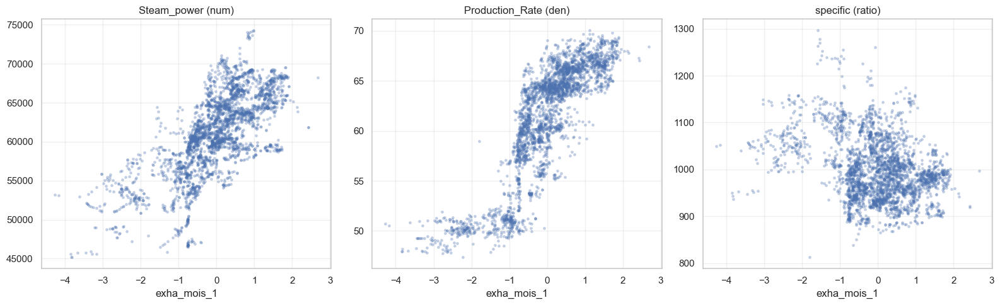

corr(exha_mois_1, Production_Rate): 0.841398375195219
corr(exha_mois_1, Steam_power):    0.708519490518916


In [8]:
import matplotlib.pyplot as plt
P = ts['Production_Rate__T/h_']
fig, ax = plt.subplots(1, 3, figsize=(16,5))
for a,(col,lab) in zip(ax, [(ts[y_column],'Steam_power (num)'),
                             (P,'Production_Rate (den)'),
                             (ts[y_column]/P,'specific (ratio)')]):
    a.scatter(Xt['exha_mois_1'].reindex(ts.index), col, s=6, alpha=0.25)
    a.set_xlabel('exha_mois_1'); a.set_title(lab); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
# correlation of exha_mois_1 with Production_Rate -> is the denominator the culprit?
e = Xt['exha_mois_1'].reindex(ts.index)
print('corr(exha_mois_1, Production_Rate):', np.corrcoef(e, P)[0,1])
print('corr(exha_mois_1, Steam_power):   ', np.corrcoef(e, ts[y_column])[0,1])


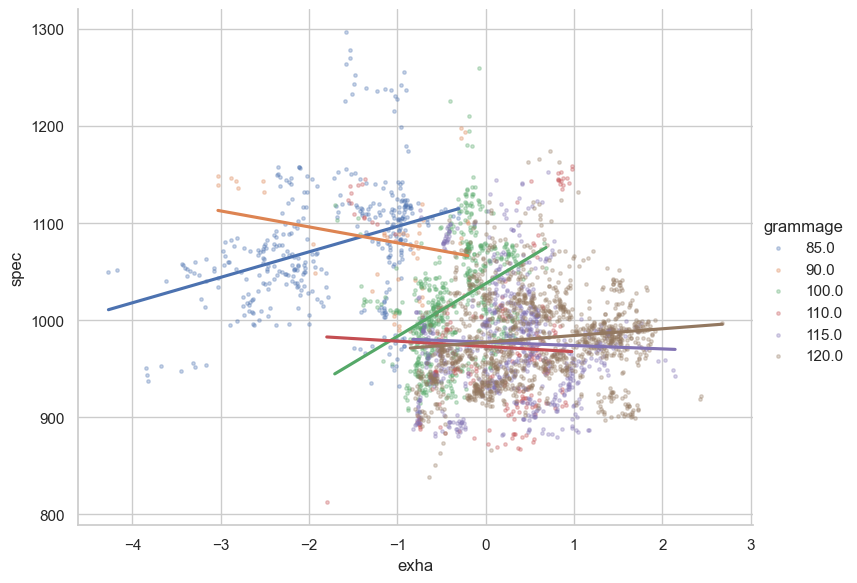

85.0 slope 26.26
90.0 slope -16.45
100.0 slope 54.42
110.0 slope -5.41
115.0 slope -3.48
120.0 slope 6.94


In [9]:
import seaborn as sns
d = pd.DataFrame({'exha': Xt['exha_mois_1'].reindex(ts.index).values,
                  'spec': (ts[y_column]/P).values,
                  'grammage': ts['grammage'].values})
sns.lmplot(data=d, x='exha', y='spec', hue='grammage', scatter_kws={'s':6,'alpha':0.3},
           height=6, aspect=1.3, ci=None)
plt.show()
# per-grade slope sign:
for g,sub in d.groupby('grammage'):
    if len(sub)>30:
        print(g, 'slope', np.polyfit(sub['exha'], sub['spec'],1)[0].round(2))


fast-component slope: -9.738756175731426


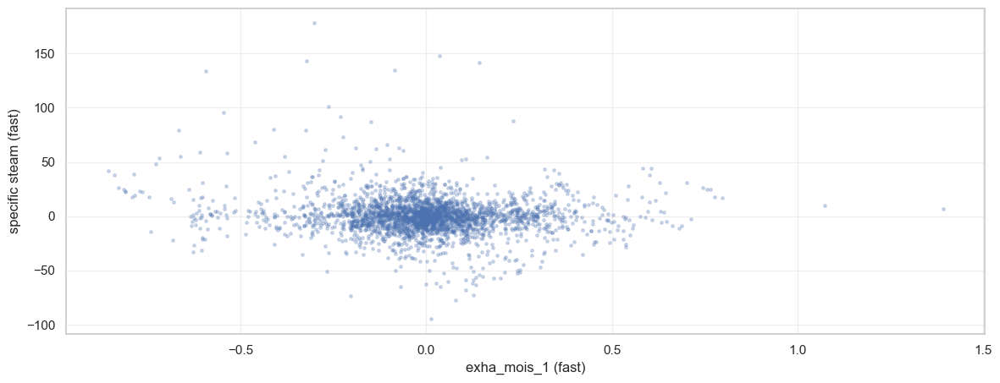

In [10]:
# fast (within-run) component = value minus a slow EWM, per segment
spec = (ts[y_column]/P)
g = ts['grammage']; seg = (g.ne(g.shift()) | ts.index.to_series().diff().gt(pd.Timedelta('12h'))).cumsum()
def fast(s):
    slow = s.groupby(seg).transform(lambda z: z.ewm(halflife='24h', times=z.index).mean())
    return s - slow
ef, sf = fast(Xt['exha_mois_1'].reindex(ts.index)), fast(spec)
ok = np.isfinite(ef)&np.isfinite(sf)
print('fast-component slope:', np.polyfit(ef[ok], sf[ok],1)[0])
plt.scatter(ef[ok], sf[ok], s=6, alpha=0.25); plt.xlabel('exha_mois_1 (fast)'); plt.ylabel('specific steam (fast)'); plt.grid(alpha=0.3); plt.show()


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.1 when using version 1.7.2. 

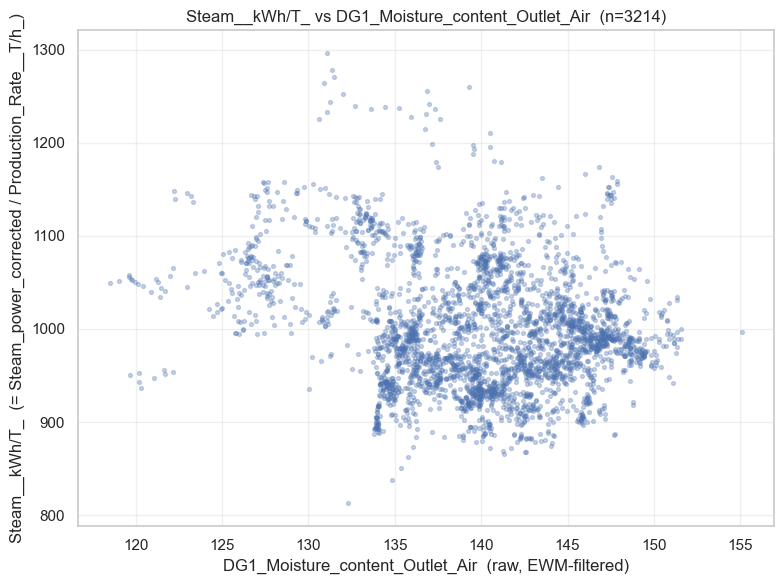

In [6]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle

# --- Load artifact + EWM'd turnup from best_path ---
art = cloudpickle.load(open(best_path / 'model_full.pkl', 'rb'))
results = json.load(open(best_path / 'results.json'))
y_column = results['parameters']['y_column']          # 'Steam_power_corrected'

ts_ewm = pd.read_parquet(best_path / 'turnup_ts.parquet')   # EWM-filtered turnup

X_COL = 'DG1_Moisture_content_Outlet_Air'               # raw column (no transform)
if X_COL not in ts_ewm.columns:
    raise KeyError(f"'{X_COL}' not in turnup columns.")

# --- Build Steam__kWh/T_ = Steam_power_corrected / Production_Rate (EWM'd) ---
DIVISOR = 'Production_Rate__T/h_'
y_power = ts_ewm[y_column].astype(float)
prod    = ts_ewm[DIVISOR].astype(float)
y_specific = y_power / prod

# --- Assemble, drop invalid rows, scatter ---
df = pd.DataFrame({'Steam__kWh/T_': y_specific.values,
                   X_COL: ts_ewm[X_COL].astype(float).values}, index=ts_ewm.index)
df = df[(prod.values > 0) & np.isfinite(df['Steam__kWh/T_']) & np.isfinite(df[X_COL])]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df[X_COL], df['Steam__kWh/T_'], s=8, alpha=0.3)
ax.set_xlabel(f'{X_COL}  (raw, EWM-filtered)')
ax.set_ylabel('Steam__kWh/T_  (= Steam_power_corrected / Production_Rate__T/h_)')
ax.set_title(f'Steam__kWh/T_ vs {X_COL}  (n={len(df)})')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Deployment

Shared EWM filter + one state column per model.

**`TurnupFilter` (one, shared across all models).** Owns the EWM filtering at a single
common halflife (`EWM_HALFLIFE`). Model-agnostic: it filters whatever columns it is told
to. The exact EWM (grade-aware, gap-segmented, time-aware `adjust=True`, softened start)
lives inside it. The engine passes the whole raw turnup, the columns to filter, and the
timestamps it wants output for; the filter slices whatever in-segment look-back it needs.
`filter_all` is the source of truth; `filter(timestamps)` matches it to ~1e-6.

**State object, one per model (`StateBuilder`).** Consumes an already-EWM-filtered frame
and computes `c(t) = y_ewm(t-k) - beta'X(t-k)` -> `Y_COLUMN + "_state"`. It runs the
model's `pre_estimator` (FeatureCreator -> PLS -> filter -> Scaler, all row-local) and the
fitted `beta`, plus lag pairing. No EWM inside it anymore.

**`ProductionModel`, one per model.** Consumes the `*_state` column and returns
`(state + beta'X) * scale * multiplier / divisor`.

**Engine flow:** load raw turnup -> `filtered = turnup_filter.filter(turnup_raw, cols, ts)`
(once, shared) -> per model `state_builder.append_state(filtered)` -> `production_model.predict(...)`.

**Hard requirement:** every deployed model must have been trained at `EWM_HALFLIFE`.


In [5]:
# Deployment objects now live in utility.py (imported by reference so cloudpickle
# bundles are portable across Python minor versions). See utility.TurnupFilter,
# StateBuilder, ProductionModel, load_state_and_prod.
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import cloudpickle

from utility import TurnupFilter, StateBuilder, ProductionModel, load_state_and_prod

print('Imported TurnupFilter, StateBuilder, ProductionModel, load_state_and_prod from utility.')


Imported TurnupFilter, StateBuilder, ProductionModel, load_state_and_prod from utility.


In [20]:
# --- Demo: shared filter -> per-model state -> predict (Wedge_Time index, reel-id select) ---
# Depends on best_path and EWM_HALFLIFE.
import sys
sys.path.insert(0, str(Path.cwd().parent))
from utility import _feature_engineering, setpoint_df
from sklearn.metrics import r2_score, mean_absolute_error

builder, prod_model = load_state_and_prod(
    best_path, use_full_model=False,   # model.pkl to reproduce test numbers
    scale=1.0, multiplier=None, divisor=None,
)
turnup_filter = TurnupFilter(halflife=EWM_HALFLIFE)
print(f'Target: {builder.y_column} | lag={builder.lag_days}d | halflife(model)={builder.ewm_halflife} '
      f'| filter halflife={turnup_filter.halflife}')

# raw turnup (feature-engineered), Wedge_Time-indexed, reel id as a column
turnup = pd.read_parquet('../data/costimiser_turnup.parquet')
turnup = _feature_engineering(turnup, setpoint_df, steam_null=False, clip=True)
turnup = turnup.set_index('Wedge_Time').sort_index()
turnup = turnup[turnup.grammage.isin([115, 120, 100, 90, 85, 110])]

# 1) shared filter (batch) -> Wedge_Time-indexed, reel id column
cols_to_filter = builder.feat_list + [builder.y_column]
filtered = turnup_filter.filter_all(turnup, cols_to_filter)

# 2) per-model state (all rows) -> Wedge_Time-indexed
filtered = builder.append_state(filtered)
print(f'Added "{builder.state_col}": {filtered[builder.state_col].notna().sum()} valid values '
      f'(index = {filtered.index.name})')

# 3) predict (batch) on rows with a valid state
eval_df = filtered[filtered[builder.state_col].notna()].copy()
y_hat = prod_model.predict(eval_df)
y_true = turnup[builder.y_column].reindex(eval_df.index).values.astype(float)
ok = ~np.isnan(y_hat) & ~np.isnan(y_true)
print(f'ProductionModel vs raw y: R2={r2_score(y_true[ok], y_hat[ok]):.4f}  '
      f'MAE={mean_absolute_error(y_true[ok], y_hat[ok]):.4f}  (n={ok.sum()})')


Target: Starch_uptake_by_paper_Bottom_Roll__g/m2_ | lag=0.1d | halflife(model)=6h | filter halflife=6h
Added "Starch_uptake_by_paper_Bottom_Roll__g/m2__state": 9628 valid values (index = Wedge_Time)
ProductionModel vs raw y: R2=-0.6169  MAE=0.2208  (n=9628)


In [21]:
# --- Save deployment bundle for the engine (cloudpickle here) ---
# Emits: deploy/turnup_filter.pkl, deploy/<engine_target stem>_bundle.pkl, deploy/manifest.json
# Engine needs: cloudpickle, numpy, pandas, and `utility` importable.
import cloudpickle, json
from pathlib import Path
from datetime import datetime, timezone

DEPLOY_DIR = Path('deploy')
DEPLOY_DIR.mkdir(exist_ok=True)

# ---- Per-model deployment config -------------------------------------------
# For a normal target leave ENGINE_TARGET=None (engine sees the true y_column).
# For a DERIVED model, set ENGINE_TARGET to the name/units the engine should see,
# and set SCALE / MULTIPLIER / DIVISOR to build the derived quantity at predict time.
#
# Example - Steam kWh/T derived from Steam_power_corrected / Production_Rate:
#     ENGINE_TARGET = 'Steam__kWh/T_'
#     UNITS         = 'kWh/T'
#     SCALE, MULTIPLIER, DIVISOR = 1.0, None, 'Production_Rate__T/h_'
# ENGINE_TARGET = None                    # None -> defaults to the model's y_column
# UNITS         = None                    # e.g. 'kWh/T'; None -> unset
# SCALE         = 1.0
# MULTIPLIER    = None
# DIVISOR       = None

#ENGINE_TARGET = 'Steam'
#ENGINE_TARGET = 'Electricity'
#ENGINE_TARGET = 'Starch Uptake Top'
ENGINE_TARGET = 'Starch Uptake Bottom'
#ENGINE_TARGET = 'SCT CD'
#ENGINE_TARGET = 'SCT MD'
#ENGINE_TARGET = 'Burst' 
#ENGINE_TARGET = 'CMT30' 
#UNITS         = 'kWh/T'
UNITS         = 'g/m2'
#UNITS         = 'g/m2'
#UNITS         = ''
SCALE         = 1.0
MULTIPLIER    = None
DIVISOR       = None


def _file_stem(name):
    """Clean stem for file names: drop unit/suffix noise from the target name."""
    stem = name
    for token in ('_by_paper', '__g/m2_', '__kWh/T_'):
        stem = stem.replace(token, '')
    return stem

# ---- 1. The shared filter (one, at EWM_HALFLIFE) ----
turnup_filter_save = TurnupFilter(halflife=EWM_HALFLIFE)
with open(DEPLOY_DIR / 'turnup_filter.pkl', 'wb') as f:
    cloudpickle.dump(turnup_filter_save, f)

# ---- 2. Per-model bundle (state builder + production model), FULL model ----
builder_save, prod_save = load_state_and_prod(
    best_path, use_full_model=True, scale=SCALE, multiplier=MULTIPLIER, divisor=DIVISOR,
    max_tolerance=1.0, fill='ffill',   # bake NaN-reduction into the shipped model
)

# engine-facing identity (label/key the engine uses). Internals stay true:
#   y_column / state_col are the real Steam_power_corrected names; the engine
#   still computes+appends state_col and calls predict() (division is internal).
engine_target = ENGINE_TARGET if ENGINE_TARGET is not None else builder_save.y_column

# model_version: UTC build time + the source experiment id (analogous to a git hash).
model_version = datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%MZ') + '_' + Path(best_path).name

model_bundle = {
    'engine_target':    engine_target,                # what the engine calls / keys on
    'units':            UNITS,
    'y_column':         builder_save.y_column,         # true internal target
    'state_col':        builder_save.state_col,        # state the engine must append
    'lag_days':         builder_save.lag_days,
    'ewm_halflife':     builder_save.ewm_halflife,
    'feat_list':        builder_save.feat_list,
    'input_features':   list(prod_save.feature_names_in_),  # incl. divisor/multiplier cols
    'scale':            prod_save.scale,
    'multiplier':       prod_save.multiplier,
    'divisor':          prod_save.divisor,
    'max_tolerance':    builder_save.max_tolerance,
    'fill':             builder_save.fill,
    'model_version':    model_version,
    'state_builder':    builder_save,
    'production_model': prod_save,
}
model_pkl = DEPLOY_DIR / f'{_file_stem(engine_target)}_bundle.pkl'
with open(model_pkl, 'wb') as f:
    cloudpickle.dump(model_bundle, f)

# ---- 3. Manifest (halflife, required columns union, model list) ----
# Keyed by engine_target so a derived model is distinct from its source target.
manifest_path = DEPLOY_DIR / 'manifest.json'
if manifest_path.exists():
    manifest = json.load(open(manifest_path))
else:
    manifest = {'ewm_halflife': EWM_HALFLIFE, 'required_columns': [], 'models': []}

manifest['ewm_halflife'] = EWM_HALFLIFE
req = set(manifest.get('required_columns', []))
req.update(builder_save.feat_list)
req.add(builder_save.y_column)
if prod_save.divisor:
    req.add(prod_save.divisor)
if prod_save.multiplier:
    req.add(prod_save.multiplier)
manifest['required_columns'] = sorted(req)

models = {m.get('engine_target', m['y_column']): m for m in manifest.get('models', [])}
models[engine_target] = {
    'engine_target': engine_target,
    'units': UNITS,
    'y_column': builder_save.y_column,
    'state_col': builder_save.state_col,
    'lag_days': builder_save.lag_days,
    'ewm_halflife': builder_save.ewm_halflife,
    'pkl': model_pkl.name,
    'input_features': list(prod_save.feature_names_in_),
    'scale': prod_save.scale,
    'multiplier': prod_save.multiplier,
    'divisor': prod_save.divisor,
    'max_tolerance': builder_save.max_tolerance,
    'fill': builder_save.fill,
    'model_version': model_version,
}
manifest['models'] = list(models.values())
json.dump(manifest, open(manifest_path, 'w'), indent=2)

print(f'Saved: {DEPLOY_DIR / "turnup_filter.pkl"}')
print(f'       {model_pkl}')
print(f'       {manifest_path}')
print(f'  engine_target={engine_target}  (y_column={builder_save.y_column}, units={UNITS})')
print(f'  scale={prod_save.scale} multiplier={prod_save.multiplier} divisor={prod_save.divisor}')
print(f'  halflife={EWM_HALFLIFE}  required_columns={len(manifest["required_columns"])}  '
      f'models={[m["engine_target"] for m in manifest["models"]]}')
print(f'  model_version={model_version}')
if builder_save.ewm_halflife != EWM_HALFLIFE:
    print(f'  WARNING: model trained at {builder_save.ewm_halflife} but filter is {EWM_HALFLIFE} '
          f'-- state will be inconsistent. Retrain this model at {EWM_HALFLIFE}.')


Saved: deploy\turnup_filter.pkl
       deploy\Starch Uptake Bottom_bundle.pkl
       deploy\manifest.json
  engine_target=Starch Uptake Bottom  (y_column=Starch_uptake_by_paper_Bottom_Roll__g/m2_, units=g/m2)
  scale=1.0 multiplier=None divisor=None
  halflife=6h  required_columns=112  models=['Steam', 'Electricity', 'Starch Uptake Top', 'Starch Uptake Top Bottom', 'SCT CD', 'SCT MD', 'Burst', 'CMT30', 'Starch Uptake Bottom']
  model_version=2026-11-19T07:55Z_261118222117


In [12]:
# --- Save deployment bundle for the engine (cloudpickle here) ---
# Emits: deploy/turnup_filter.pkl, deploy/<engine_target stem>_bundle.pkl, deploy/manifest.json
# Engine needs: cloudpickle, numpy, pandas, and `utility` importable.
import cloudpickle, json
from pathlib import Path
from datetime import datetime, timezone

DEPLOY_DIR = Path('deploy')
DEPLOY_DIR.mkdir(exist_ok=True)

# ---- Per-model deployment config -------------------------------------------
# For a normal target leave ENGINE_TARGET=None (engine sees the true y_column).
# For a DERIVED model, set ENGINE_TARGET to the name/units the engine should see,
# and set SCALE / MULTIPLIER / DIVISOR to build the derived quantity at predict time.
#
# Example - Steam kWh/T derived from Steam_power_corrected / Production_Rate:
#     ENGINE_TARGET = 'Steam__kWh/T_'
#     UNITS         = 'kWh/T'
#     SCALE, MULTIPLIER, DIVISOR = 1.0, None, 'Production_Rate__T/h_'
# ENGINE_TARGET = None                    # None -> defaults to the model's y_column
# UNITS         = None                    # e.g. 'kWh/T'; None -> unset
# SCALE         = 1.0
# MULTIPLIER    = None
# DIVISOR       = None

ENGINE_TARGET = 'Steam__kWh/T_'
UNITS         = 'kWh/T'
SCALE         = 1.0
MULTIPLIER    = None
DIVISOR       = 'Production_Rate__T/h_'


def _file_stem(name):
    """Clean stem for file names: drop unit/suffix noise from the target name."""
    stem = name
    for token in ('_by_paper', '__g/m2_', '__kWh/T_'):
        stem = stem.replace(token, '')
    return stem

# ---- 1. The shared filter (one, at EWM_HALFLIFE) ----
turnup_filter_save = TurnupFilter(halflife=EWM_HALFLIFE)
with open(DEPLOY_DIR / 'turnup_filter.pkl', 'wb') as f:
    cloudpickle.dump(turnup_filter_save, f)

# ---- 2. Per-model bundle (state builder + production model), FULL model ----
builder_save, prod_save = load_state_and_prod(
    best_path, use_full_model=True, scale=SCALE, multiplier=MULTIPLIER, divisor=DIVISOR,
    max_tolerance=1.0, fill='ffill',   # bake NaN-reduction into the shipped model
)

# engine-facing identity (label/key the engine uses). Internals stay true:
#   y_column / state_col are the real Steam_power_corrected names; the engine
#   still computes+appends state_col and calls predict() (division is internal).
engine_target = ENGINE_TARGET if ENGINE_TARGET is not None else builder_save.y_column

# model_version: UTC build time + the source experiment id (analogous to a git hash).
model_version = datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%MZ') + '_' + Path(best_path).name

model_bundle = {
    'engine_target':    engine_target,                # what the engine calls / keys on
    'units':            UNITS,
    'y_column':         builder_save.y_column,         # true internal target
    'state_col':        builder_save.state_col,        # state the engine must append
    'lag_days':         builder_save.lag_days,
    'ewm_halflife':     builder_save.ewm_halflife,
    'feat_list':        builder_save.feat_list,
    'input_features':   list(prod_save.feature_names_in_),  # incl. divisor/multiplier cols
    'scale':            prod_save.scale,
    'multiplier':       prod_save.multiplier,
    'divisor':          prod_save.divisor,
    'max_tolerance':    builder_save.max_tolerance,
    'fill':             builder_save.fill,
    'model_version':    model_version,
    'state_builder':    builder_save,
    'production_model': prod_save,
}
model_pkl = DEPLOY_DIR / f'{_file_stem(engine_target)}_bundle.pkl'
with open(model_pkl, 'wb') as f:
    cloudpickle.dump(model_bundle, f)

# ---- 3. Manifest (halflife, required columns union, model list) ----
# Keyed by engine_target so a derived model is distinct from its source target.
manifest_path = DEPLOY_DIR / 'manifest.json'
if manifest_path.exists():
    manifest = json.load(open(manifest_path))
else:
    manifest = {'ewm_halflife': EWM_HALFLIFE, 'required_columns': [], 'models': []}

manifest['ewm_halflife'] = EWM_HALFLIFE
req = set(manifest.get('required_columns', []))
req.update(builder_save.feat_list)
req.add(builder_save.y_column)
if prod_save.divisor:
    req.add(prod_save.divisor)
if prod_save.multiplier:
    req.add(prod_save.multiplier)
manifest['required_columns'] = sorted(req)

models = {m.get('engine_target', m['y_column']): m for m in manifest.get('models', [])}
models[engine_target] = {
    'engine_target': engine_target,
    'units': UNITS,
    'y_column': builder_save.y_column,
    'state_col': builder_save.state_col,
    'lag_days': builder_save.lag_days,
    'ewm_halflife': builder_save.ewm_halflife,
    'pkl': model_pkl.name,
    'input_features': list(prod_save.feature_names_in_),
    'scale': prod_save.scale,
    'multiplier': prod_save.multiplier,
    'divisor': prod_save.divisor,
    'max_tolerance': builder_save.max_tolerance,
    'fill': builder_save.fill,
    'model_version': model_version,
}
manifest['models'] = list(models.values())
json.dump(manifest, open(manifest_path, 'w'), indent=2)

print(f'Saved: {DEPLOY_DIR / "turnup_filter.pkl"}')
print(f'       {model_pkl}')
print(f'       {manifest_path}')
print(f'  engine_target={engine_target}  (y_column={builder_save.y_column}, units={UNITS})')
print(f'  scale={prod_save.scale} multiplier={prod_save.multiplier} divisor={prod_save.divisor}')
print(f'  halflife={EWM_HALFLIFE}  required_columns={len(manifest["required_columns"])}  '
      f'models={[m["engine_target"] for m in manifest["models"]]}')
print(f'  model_version={model_version}')
if builder_save.ewm_halflife != EWM_HALFLIFE:
    print(f'  WARNING: model trained at {builder_save.ewm_halflife} but filter is {EWM_HALFLIFE} '
          f'-- state will be inconsistent. Retrain this model at {EWM_HALFLIFE}.')


Saved: deploy\turnup_filter.pkl
       deploy\Steam_bundle.pkl
       deploy\manifest.json
  engine_target=Steam__kWh/T_  (y_column=Steam_power_corrected, units=kWh/T)
  scale=1.0 multiplier=None divisor=Production_Rate__T/h_
  halflife=6h  required_columns=94  models=['SCT CD', 'SCT MD', 'Burst', 'CMT30', 'Starch Uptake Top', 'Starch Uptake Bottom', 'Electricity', 'Steam', 'Steam__kWh/T_']
  model_version=2026-09-17T10:00Z_260917092416


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.1 when using version 1.7.2. 

In [82]:
# --- Equivalence tests (Wedge_Time index, reel-id selection) ---
import numpy as np, pandas as pd

cols_to_filter = builder_save.feat_list + [builder_save.y_column]
filtered_all = turnup_filter_save.filter_all(turnup, cols_to_filter)   # Wedge_Time-indexed

# segment-oldest rows differ by design (softened start needs a NEWER row); excluded below.
seg = pd.Series(turnup_filter_save.segments(turnup), index=turnup.sort_index().index)
is_oldest = ~seg.duplicated(keep='first')
oldest_reels = set(turnup.sort_index().loc[is_oldest.values, 'MBS_Current_reel_ID'].values)
id_all = turnup.sort_index()['MBS_Current_reel_ID'].values
non_oldest_reels = [r for r in id_all if r not in oldest_reels]

# (a) filter(reel_ids) == filter_all on the selected non-oldest reels (exact)
sample_reels = list(np.array(non_oldest_reels)[np.linspace(0, len(non_oldest_reels)-1, 25).astype(int)])
fp = turnup_filter_save.filter(turnup, cols_to_filter, sample_reels)
# align by reel id (Wedge_Time index differs only in ordering)
fp_by_id = fp.set_index('MBS_Current_reel_ID')
fa_by_id = filtered_all.set_index('MBS_Current_reel_ID')
diff = fp_by_id.loc[sample_reels, cols_to_filter].values - fa_by_id.loc[sample_reels, cols_to_filter].values
print(f'(a) filter vs filter_all (non-oldest reels)  max|diff| = {np.nanmax(np.abs(diff)):.2e}')

# (b) engine path (shared filter -> state) == all-in-one
state_engine = builder_save.append_state(filtered_all.copy())[builder_save.state_col].values
state_allin1 = builder_save.append_state_from_raw(turnup, turnup_filter_save)[builder_save.state_col].values
m = ~np.isnan(state_engine) & ~np.isnan(state_allin1)
print(f'(b) state engine vs all-in-one  max|diff| = {np.nanmax(np.abs(state_engine[m]-state_allin1[m])):.2e}  (n={m.sum()})')

# (c) reel-id selection in append_state: subset == full on selected reels
sel = sample_reels[:8]
full_state = builder_save.append_state(filtered_all.copy())
sub_state  = builder_save.append_state(filtered_all.copy(), reel_ids=sel)
fs = full_state.set_index('MBS_Current_reel_ID')[builder_save.state_col].reindex(sel).values
ss = sub_state.set_index('MBS_Current_reel_ID')[builder_save.state_col].reindex(sel).values
mm = ~np.isnan(fs) & ~np.isnan(ss)
print(f'(c) append_state(reel_ids) vs full  max|diff| = {np.nanmax(np.abs(fs[mm]-ss[mm])) if mm.any() else 0:.2e}  '
      f'(selected n={mm.sum()})')
print('    (a), (b), (c) should be ~1e-6 or smaller.')


(a) filter vs filter_all (non-oldest reels)  max|diff| = 0.00e+00
(b) state engine vs all-in-one  max|diff| = 0.00e+00  (n=9594)
(c) append_state(reel_ids) vs full  max|diff| = 0.00e+00  (selected n=8)
    (a), (b), (c) should be ~1e-6 or smaller.


In [ ]:
# --- Engine-side usage (run this in the OTHER project) ---
# Requirements: cloudpickle, numpy, pandas, and `utility` importable (SAME version as
# training -- the deploy classes now live in utility.py). Pass the raw turnup
# Wedge_Time-indexed with MBS_Current_reel_ID as a column.
#
#   import cloudpickle, json, pandas as pd
#   manifest = json.load(open('deploy/manifest.json'))
#   turnup_filter = cloudpickle.load(open('deploy/turnup_filter.pkl', 'rb'))
#   cols = manifest['required_columns']
#
#   # COLD START (empty cache): filter everything, state for all rows.
#   filtered = turnup_filter.filter_all(turnup, cols)
#   for m in manifest['models']:
#       bundle = cloudpickle.load(open('deploy/' + m['pkl'], 'rb'))
#       sb, pm = bundle['state_builder'], bundle['production_model']
#       filt_m = sb.append_state(filtered, reel_ids=None)      # NaN at edge rows, no error
#       y_hat  = pm.predict(filt_m[filt_m[bundle['state_col']].notna()])
#
#   # INCREMENTAL (cache warm): request recent reels. Pass lag_days so filter() also
#   # returns each reel's t-k lag partner + EWM warm-up (needed by append_state).
#   reel_ids = turnup['MBS_Current_reel_ID'].iloc[-1:]
#   for m in manifest['models']:
#       bundle = cloudpickle.load(open('deploy/' + m['pkl'], 'rb'))
#       sb, pm = bundle['state_builder'], bundle['production_model']
#       filtered = turnup_filter.filter(turnup, cols, reel_ids, lag_days=m['lag_days'])
#       filt_m   = sb.append_state(filtered, reel_ids=reel_ids)  # state for those reels
#       y_hat    = pm.predict(filt_m[filt_m[bundle['state_col']].notna()])
#
# Selection is by reel id (stable key); index stays Wedge_Time; reel id is a column so you
# can splice on it. Old rows are frozen (EWM causal) -> cache filtered output, request
# recent reels. IMPORTANT: for the incremental path, pass lag_days to filter() so the
# lag partners (t-k) and warm-up are included -- otherwise append_state returns NaN.
# (If running several models with different lags off one filtered frame, use the MAX
# lag_days across them.)
#
# MODEL IDENTITY / DERIVED MODELS:
#   - Match/label a model by m['engine_target'] (NOT y_column). For most models
#     engine_target == y_column. For a DERIVED model (e.g. steam kWh/T) engine_target
#     is the name the engine should show (e.g. 'Steam__kWh/T_', units in m['units']),
#     while y_column/state_col stay the true internal names.
#   - Always compute+append m['state_col'] (the internal state), regardless of
#     engine_target. e.g. steam kWh/T uses state_col='Steam_power_corrected_state'.
#   - predict() already applies scale/multiplier/divisor internally, so y_hat is in the
#     engine_target's units directly (e.g. kWh/T = Steam_power_corrected / Production_Rate).
#     The divisor/multiplier columns are in m['input_features'] and required_columns,
#     so just make sure turnup carries them (e.g. Production_Rate__T/h_).
print('Engine-side usage documented above.')
